# 02 - Preprocesamiento

Las funciones viven en `src/preprocessing.py`; este notebook las usa y muestra su efecto.

Pipeline: **detrending** (restar mediana móvil) -> **recorte de picos hacia arriba** -> **normalización**.

Decisiones: ventana de mediana = 101 puntos (~50 h con cadencia de 30 min); recorte en 4 desviaciones robustas.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
from src.data import load_train_test
from src.preprocessing import detrend_median, clip_upward_outliers, normalize, preprocess

X_train, y_train, X_test, y_test = load_train_test()

## 1. Elección de la ventana del filtro de mediana

Compromiso: ventana muy chica -> el filtro absorbe el tránsito como si fuera tendencia; ventana muy grande -> queda tendencia sin quitar. Probamos 4 tamaños sobre 3 estrellas con planeta.

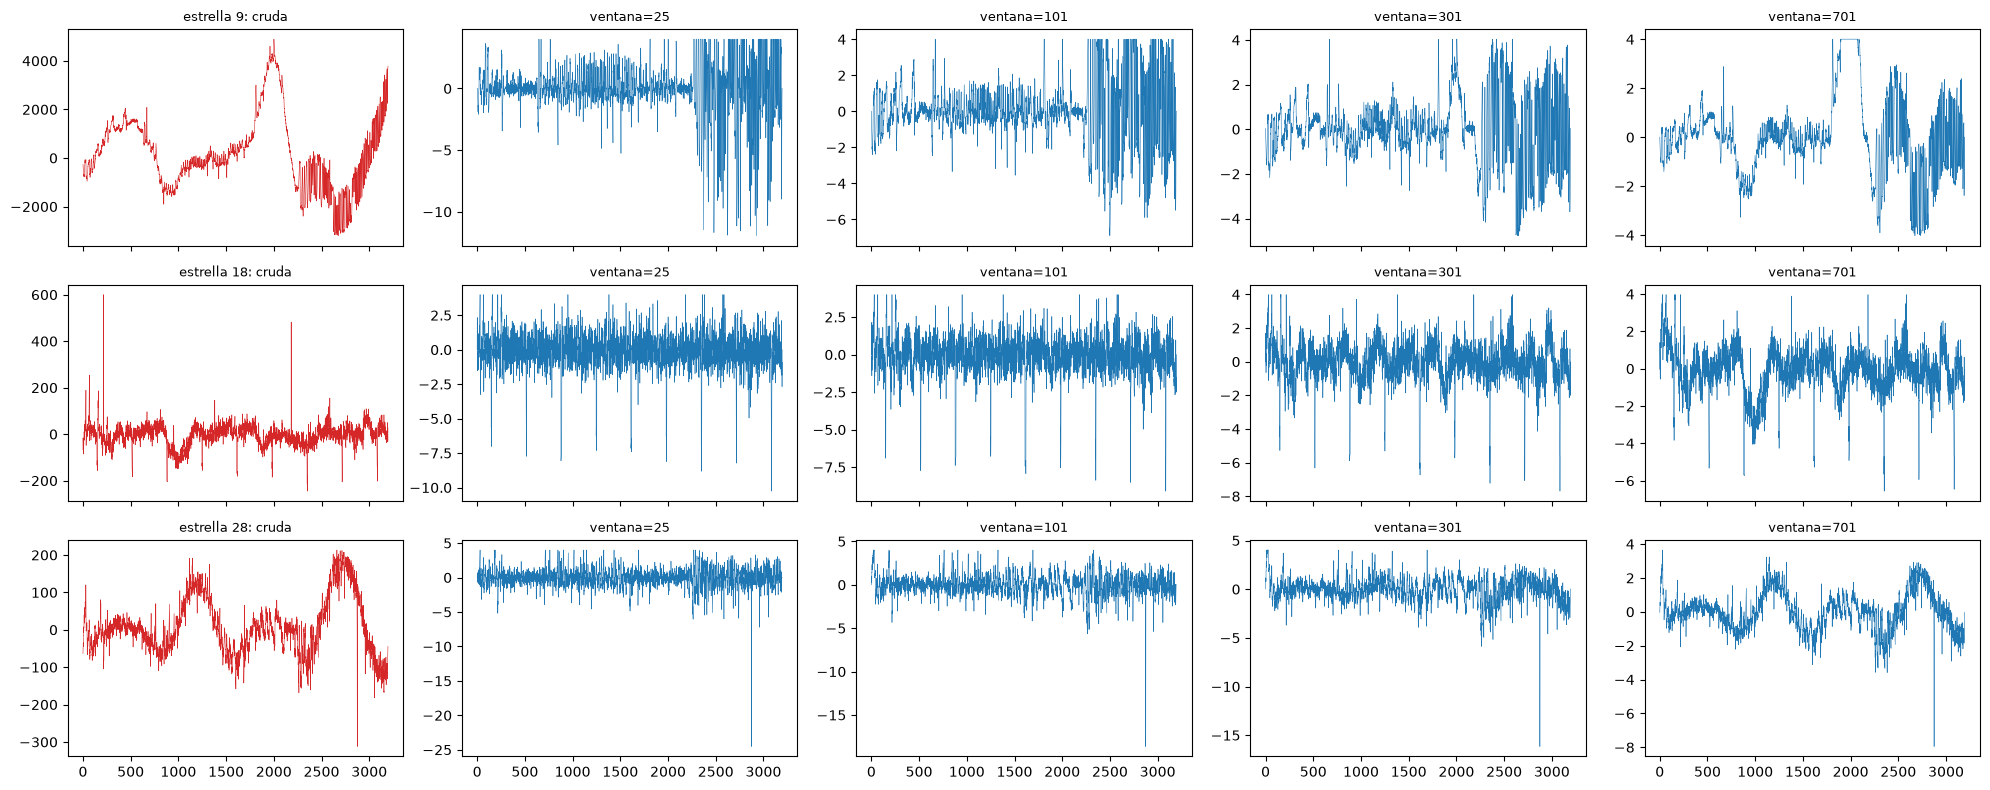

In [2]:
idx = [9, 18, 28]
windows = [25, 101, 301, 701]
fig, axes = plt.subplots(len(idx), len(windows) + 1, figsize=(20, 8), sharex=True)
for r, i in enumerate(idx):
    axes[r, 0].plot(X_train[i], lw=0.4, color='tab:red')
    axes[r, 0].set_title(f'estrella {i}: cruda', fontsize=9)
    for c, w in enumerate(windows, start=1):
        z = normalize(clip_upward_outliers(detrend_median(X_train[i], w)))[0]
        axes[r, c].plot(z, lw=0.4, color='tab:blue')
        axes[r, c].set_title(f'ventana={w}', fontsize=9)
plt.tight_layout()
plt.savefig('../results/02_ventanas.png', dpi=100)
plt.show()

**Conclusión:** con 25 y 101 se ven caídas periódicas en la estrella 18 que en la curva cruda eran invisibles; con 701 queda tendencia sin quitar. Elegimos **101**: más margen que 25 para no absorber tránsitos largos y suficiente para eliminar la tendencia. Se volverá a variar en el estudio de ablación.

## 2. Aplicar el pipeline a todo el dataset

In [3]:
Z_train = preprocess(X_train, window=101, n_sigma=4.0)
Z_test = preprocess(X_test, window=101, n_sigma=4.0)
print('train:', Z_train.shape, '| test:', Z_test.shape)
print('NaN:', np.isnan(Z_train).sum(), np.isnan(Z_test).sum())
print('mediana de cada curva ~0:', np.abs(np.median(Z_train, axis=1)).max())
print('máximo tras recorte (en sigmas):', Z_train.max().round(2), '| mínimo:', Z_train.min().round(2))

train: (5087, 3197) | test: (570, 3197)
NaN: 0 0
mediana de cada curva ~0: 0.0
máximo tras recorte (en sigmas): 4.07 | mínimo: -1481.72


Tras el pipeline todas las curvas están en la misma escala (desviación robusta = 1). El máximo queda acotado por el recorte (~4), pero el mínimo no: las caídas (candidatos a tránsito) se conservan.

**Caso borde detectado:** 4 estrellas de train (todas sin planeta: índices 1908, 2226, 3136, 4186) tienen oscilaciones enormes y, tras el detrending, más del 58% de sus puntos quedan exactamente en 0. Su MAD (desviación robusta) es 0 y al normalizar se dividía casi por cero (valores de hasta -1e16). `robust_std` usa en esos casos la desviación estándar común. Aun así quedan estrellas con mínimos muy negativos (la peor: -1.481 sigmas, estrella 2381, sin planeta), pero son pocas: la mediana del mínimo por estrella es -6,6.

## 3. Antes y después

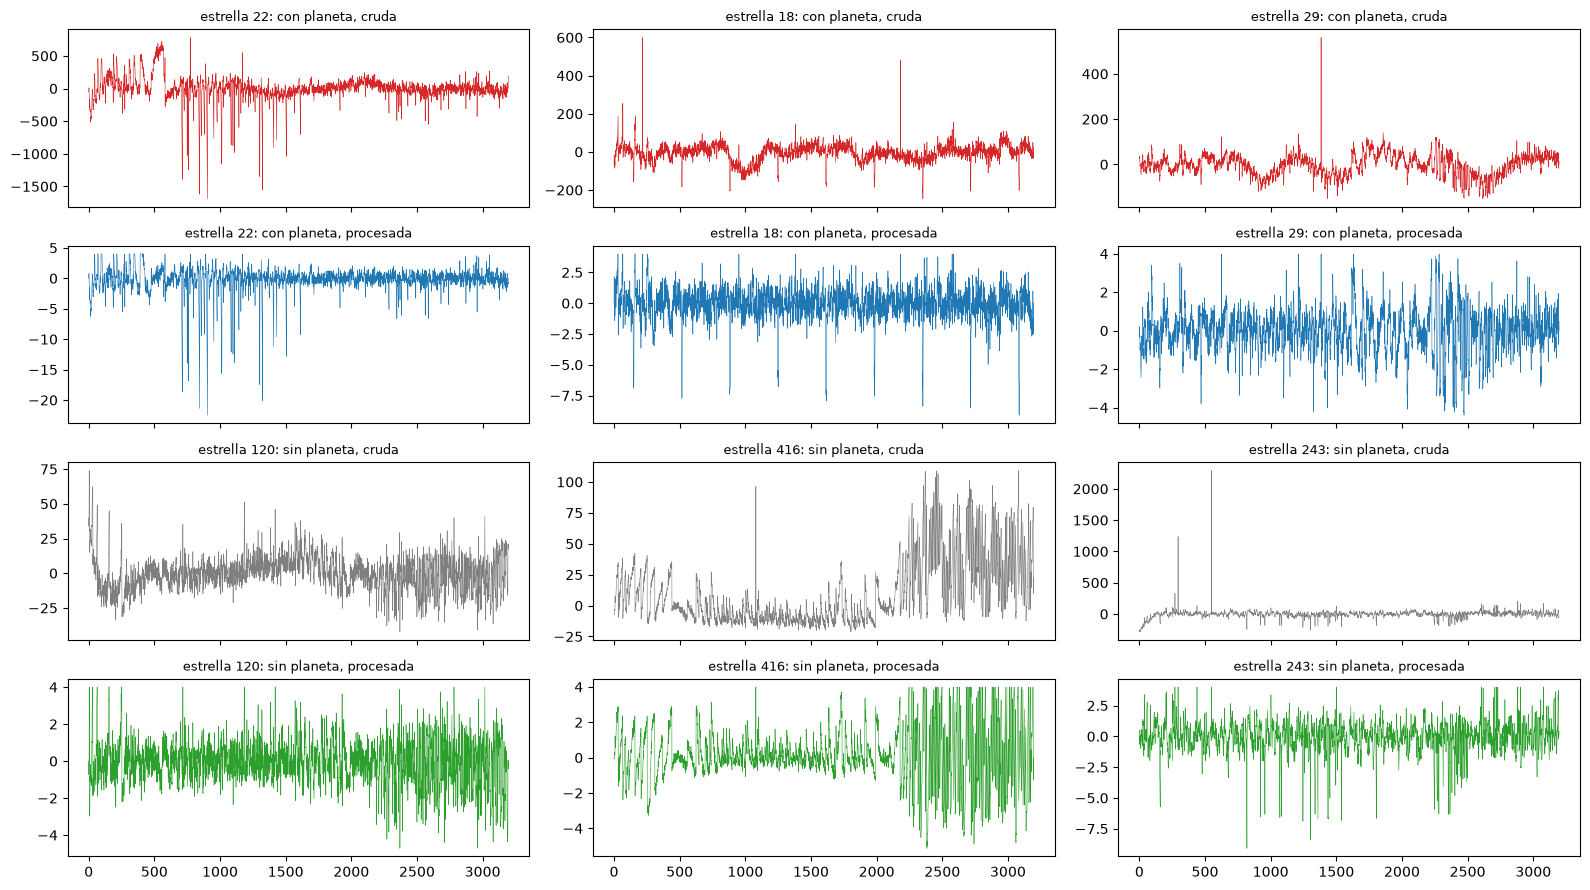

In [4]:
rng = np.random.default_rng(0)
con = rng.choice(np.where(y_train == 1)[0], 3, replace=False)
sin = rng.choice(np.where(y_train == 0)[0], 3, replace=False)
fig, axes = plt.subplots(4, 3, figsize=(16, 9), sharex=True)
for col in range(3):
    for fila, (i, Xd, titulo, color) in enumerate([
            (con[col], X_train, 'con planeta, cruda', 'tab:red'),
            (con[col], Z_train, 'con planeta, procesada', 'tab:blue'),
            (sin[col], X_train, 'sin planeta, cruda', 'tab:gray'),
            (sin[col], Z_train, 'sin planeta, procesada', 'tab:green')]):
        axes[fila, col].plot(Xd[i], lw=0.4, color=color)
        axes[fila, col].set_title(f'estrella {i}: {titulo}', fontsize=9)
plt.tight_layout()
plt.savefig('../results/02_antes_despues.png', dpi=100)
plt.show()

**Observación:** el pipeline hace visibles caídas que en la curva cruda no se ven. En la estrella 18 (con planeta) aparecen caídas regulares, muy probablemente tránsitos. Pero el resultado **no es una separación limpia**: la estrella 22 (con planeta) tiene caídas profundas pero irregulares, la 29 (con planeta) no muestra caídas evidentes, y la 243 (sin planeta) también tiene caídas de hasta -7,5 sigmas. Mirar las curvas no basta: esto justifica usar BLS, que busca específicamente caídas **periódicas**, y modelos que aprendan a distinguirlas.